<a href="https://colab.research.google.com/github/szhang2187/Datathon_For_Social_Good_8/blob/data_cleaning_step_3/03_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 3: Analysis and findings

**Question:** How do the availability and quality (review ratings) of essential services vary with median household income across Bay Area ZIPs?

This notebook answers four parts of it, comparing ZIP income quintiles (Q1 = lowest fifth of ZIPs by median household income, Q5 = highest):

1. **Availability:** sites per 10,000 residents for each service type
2. **Deserts:** how often a ZIP has none of a service
3. **Quality:** median rating (plus mean and low-rated share) for grocery, pharmacy, bank and clinic
4. **Complaints (exploratory):** what 1-2 star clinic reviews talk about in lower- vs. higher-income ZIPs

**Inputs** (made by notebooks 01 and 02): `zip_table.csv`, `places_clean.csv`, `reviews_low.csv` in `datathon/data/processed/` on Drive (or `data/processed/` locally).
**Outputs:** charts in `figures/`, summary tables and `key_findings.md` in `results/`. The method is written up in the **Methodology** section at the end.

In [1]:
# Setup: libraries, where the data lives, where outputs go.
# In Colab this mounts Drive and reads the files notebooks 01 and 02 saved there.
# Locally it reads data/processed/ in the repo folder (or the folder in the DATATHON_DATA environment variable).
import os, sys, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

GITHUB = "https://raw.githubusercontent.com/szhang2187/Datathon_For_Social_Good_8/main"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    candidates = ["/content/drive/MyDrive/datathon/data/processed", "/content/drive/MyDrive"]
    ROOT = "/content/drive/MyDrive/datathon"
else:
    candidates = [os.environ.get("DATATHON_DATA", ""), "data/processed", "."]
    ROOT = os.environ.get("DATATHON_OUT", ".")                # the repo folder

# Use the first folder that has zip_table.csv; otherwise read the CSVs committed to GitHub (main branch).
DATA = next((c for c in candidates if c and os.path.exists(os.path.join(c, "zip_table.csv"))), GITHUB)

def data_path(name):
    """Where to read a data file from, or None if it isn't available locally or on GitHub."""
    if DATA != GITHUB:
        local = os.path.join(DATA, name)
        others = [os.path.join(c, name) for c in candidates if c]
        return next((p for p in [local] + others if os.path.exists(p)), None)
    return f"{GITHUB}/{name}"

FIG = os.path.join(ROOT, "figures")
RES = os.path.join(ROOT, "results")
os.makedirs(FIG, exist_ok=True)
os.makedirs(RES, exist_ok=True)

SEED = 42          # every random step (bootstraps, samples) uses this, so reruns give the same numbers
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
print("reading from:", DATA)
print("saving figures to:", FIG, "| tables to:", RES)

reading from: .
saving figures to: .\figures | tables to: .\results


In [2]:
# Names, groups and chart style used throughout.
TYPES = ["grocery", "pharmacy", "clinic", "bank", "food_bank", "bus_stop", "school"]
LABEL = {"grocery": "Grocery", "pharmacy": "Pharmacy", "clinic": "Clinic/hospital", "bank": "Bank",
         "food_bank": "Food bank", "bus_stop": "Bus stop", "school": "School"}
RATED = ["grocery", "pharmacy", "clinic", "bank"]       # schools, bus stops, food banks have too few reviews
Q = ["Q1", "Q2", "Q3", "Q4", "Q5"]
LOWER, HIGHER = "Lower income (Q1-Q2)", "Higher income (Q4-Q5)"

# Colors: one blue ramp for the ordered quintiles (light = lower income), orange vs. blue for lower vs. higher.
Q_COLORS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
SIDE_COLORS = {LOWER: "#eb6834", HIGHER: "#2a78d6"}
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "figure.dpi": 110,
})

def save(fig, name):
    fig.savefig(os.path.join(FIG, name), dpi=200, bbox_inches="tight")

def to_bool(s):
    """A CSV round trip can turn True/False into text. Make them real booleans (missing = False)."""
    if s.dtype == bool:
        return s
    return s.astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])

def holm(pvals):
    """Holm adjustment: we test 7 (or 4) service types at once, so each p-value is scaled up to keep
    the chance of any false alarm at 5%."""
    p = np.asarray(pvals, float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    m = ok.sum()
    if m == 0:
        return out
    order = np.argsort(p[ok])
    adj = np.minimum(np.maximum.accumulate((m - np.arange(m)) * p[ok][order]), 1)
    tmp = np.empty(m)
    tmp[order] = adj
    out[ok] = tmp
    return out

def trend_test(events, totals):
    """Cochran-Armitage test: does a share (e.g. ZIPs with no pharmacy) rise or fall steadily from Q1 to Q5?
    Returns z (negative = share falls as income rises) and a two-sided p-value."""
    x, n = np.asarray(events, float), np.asarray(totals, float)
    s = np.arange(1, len(n) + 1)
    N, pbar = n.sum(), x.sum() / n.sum()
    var = pbar * (1 - pbar) * (np.sum(n * s**2) - np.sum(n * s) ** 2 / N)
    if var <= 0:
        return np.nan, np.nan
    z = np.sum(s * (x - n * pbar)) / np.sqrt(var)
    return z, 2 * stats.norm.sf(abs(z))

def boot_ci(x, fn=np.median, reps=2000):
    """95% bootstrap interval for a median (or mean): resample the values with replacement 2,000 times."""
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    if len(x) < 2:
        return np.nan, np.nan
    rng = np.random.default_rng(SEED)
    stat = fn(rng.choice(x, size=(reps, len(x)), replace=True), axis=1)
    return tuple(np.percentile(stat, [2.5, 97.5]))

def spearman(x, y):
    """Spearman rank correlation, or NaN when there is too little data or no variation."""
    x, y = pd.Series(x).reset_index(drop=True), pd.Series(y).reset_index(drop=True)
    ok = x.notna() & y.notna()
    if ok.sum() < 5 or x[ok].nunique() < 2 or y[ok].nunique() < 2:
        return np.nan, np.nan
    r = stats.spearmanr(x[ok], y[ok])
    return float(r.statistic), float(r.pvalue)

def fmt_p(p):
    return "n/a" if pd.isna(p) else ("<0.001" if p < 0.001 else f"{p:.3f}")

## 0. Load the data and define the income groups

In [3]:
zt = pd.read_csv(data_path("zip_table.csv"), dtype={"zip": str, "county_fips": str})
places = pd.read_csv(data_path("places_clean.csv"), dtype={"zip": str})

# reviews_low.csv is only needed for section 4 (clinic complaints); skip that section if it's missing
HAVE_REVIEWS = False
try:
    p = data_path("reviews_low.csv")
    rev = pd.read_csv(p, dtype={"zip": str}) if p else None
    HAVE_REVIEWS = rev is not None
except Exception as e:                       # e.g. not on GitHub yet (HTTP 404)
    rev = None
if not HAVE_REVIEWS:
    print("reviews_low.csv not found: section 4 (clinic complaints) will be skipped.")

for c in [c for c in zt.columns if c.startswith("has_none_")]:
    zt[c] = to_bool(zt[c])
for c in ["enough_reviews", "is_chain", "is_site"]:
    places[c] = to_bool(places[c])
places["type"] = places["service_type"].str.replace("clinic/hospital", "clinic").str.replace(" ", "_")

# CHECK: the columns this notebook relies on are all there
need = [f"{p}_{t}" for t in TYPES for p in ["sites", "sites_per_10k", "has_none"]]
need += ["zip", "population", "median_income", "income_group", "county"]
missing = [c for c in need if c not in zt.columns]
assert not missing, f"zip_table.csv is missing columns: {missing}"
print("zip_table:", zt.shape, "| places_clean:", places.shape, "| reviews_low:", rev.shape if HAVE_REVIEWS else "missing")

reviews_low.csv not found: section 4 (clinic complaints) will be skipped.
zip_table: (261, 59) | places_clean: (89455, 15) | reviews_low: missing


In [4]:
# Analysis table: ZIPs that have an income group. ZIPs with no income estimate can't be put in a quintile.
zq = zt[zt["income_group"].notna()].copy()
zq["income_group"] = pd.Categorical(zq["income_group"], categories=Q, ordered=True)
print("ZIPs in zip_table:", len(zt), "| with an income group:", len(zq), "| left out (no income):", len(zt) - len(zq))

# What each quintile is: income range, size, and how many ZIPs sit at the Census $250,001 cap
g = zq.groupby("income_group", observed=True)
quint = pd.DataFrame({
    "zips": g.size(),
    "residents": g["population"].sum(),
    "median_zip_population": g["population"].median(),
    "income_min": g["median_income"].min(),
    "income_median": g["median_income"].median(),
    "income_max": g["median_income"].max(),
    "zips_at_250001_cap": g["median_income"].apply(lambda s: int((s >= 250001).sum())),
})
quint.to_csv(f"{RES}/00_income_quintiles.csv")
quint.style.format({"residents": "{:,.0f}", "median_zip_population": "{:,.0f}",
                    "income_min": "${:,.0f}", "income_median": "${:,.0f}", "income_max": "${:,.0f}"})

ZIPs in zip_table: 261 | with an income group: 259 | left out (no income): 2


,zips,residents,median_zip_population,income_min,income_median,income_max,zips_at_250001_cap
income_group,,,,,,,
Q1,52,"1,418,525","23,796","$50,129","$86,694","$103,054",0
Q2,52,"1,546,768","28,230","$103,549","$113,942","$122,966",0
Q3,51,"1,816,059","34,592","$124,130","$135,635","$151,524",0
Q4,52,"1,617,739","31,919","$151,609","$171,388","$196,690",0
Q5,52,"1,218,460","21,670","$196,882","$222,986","$250,001",12


In [5]:
# CONTEXT: who lives in each quintile (resident-weighted shares).
# Income moves together with race, car ownership and language, so a pattern by income is never income alone.
def wshare(num, den):
    return g[num].sum() / g[den].sum()

demo = pd.DataFrame({
    "% white": wshare("white", "race_total"), "% Black": wshare("black", "race_total"),
    "% Asian": wshare("asian", "race_total"), "% Hispanic": wshare("hispanic", "race_total"),
    "% households no car": wshare("no_car_households", "households"),
    "% limited-English households": wshare("limited_english_households", "lang_households"),
})
demo.to_csv(f"{RES}/00_demographics_by_quintile.csv")
(demo * 100).round(1)

,% white,% Black,% Asian,% Hispanic,% households no car,% limited-English households
income_group,,,,,,
Q1,24.7,11.0,18.5,39.2,15.6,11.8
Q2,36.1,7.4,19.6,29.7,10.6,8.1
Q3,34.1,4.6,29.4,25.1,7.6,8.2
Q4,34.8,2.4,38.1,17.9,8.7,8.5
Q5,44.4,1.7,37.5,9.6,6.0,5.3


## 1. Availability: sites per 10,000 residents

For each ZIP, **sites per 10k = distinct sites ÷ population × 10,000** (from `zip_table`, using `is_site` so a medical building with 40 listed doctors counts once).
Per quintile we report two numbers:

* **Median ZIP**: the typical neighborhood in that quintile (not pulled up by a dense downtown ZIP). The 95% interval comes from a bootstrap over ZIPs.
* **Pooled**: all sites ÷ all residents in the quintile, i.e. what the average resident sees.

The trend is the **Spearman rank correlation** between ZIP median income and sites per 10k across all ZIPs (positive = more sites in richer ZIPs). P-values are Holm-adjusted for testing seven services.

In [6]:
long_rows, wide_rows = [], []
for t in TYPES:
    rate = f"sites_per_10k_{t}"
    gq = zq.groupby("income_group", observed=True)
    med = gq[rate].median()
    pooled = gq[f"sites_{t}"].sum() / gq["population"].sum() * 10000
    for q in Q:
        vals = zq.loc[zq["income_group"] == q, rate]
        lo, hi = boot_ci(vals, np.median)
        mlo, mhi = boot_ci(vals, np.mean)
        long_rows.append({"service": LABEL[t], "type": t, "quintile": q, "zips": len(vals),
                          "sites": int(zq.loc[zq["income_group"] == q, f"sites_{t}"].sum()),
                          "median_per_10k": med[q], "ci_low": lo, "ci_high": hi,
                          "mean_per_10k": vals.mean(), "mean_ci_low": mlo, "mean_ci_high": mhi,
                          "pooled_per_10k": pooled[q]})
    rho, p = spearman(zq["median_income"], zq[rate])
    wide_rows.append({"service": LABEL[t], **{q: med[q] for q in Q},
                      "Q1 ÷ Q5": med["Q1"] / med["Q5"] if med["Q5"] > 0 else np.nan,
                      "pooled Q1": pooled["Q1"], "pooled Q5": pooled["Q5"],
                      "spearman_rho": rho, "p": p})

avail_long = pd.DataFrame(long_rows)
avail = pd.DataFrame(wide_rows)
avail["p_holm"] = holm(avail["p"])
avail_long.to_csv(f"{RES}/01_availability_by_quintile.csv", index=False)
avail.to_csv(f"{RES}/01_availability_summary.csv", index=False)

print("Median ZIP: sites per 10,000 residents, by income quintile (Q1 = lowest income)")
avail.set_index("service").round(3)

Median ZIP: sites per 10,000 residents, by income quintile (Q1 = lowest income)


,Q1,Q2,Q3,Q4,Q5,Q1 ÷ Q5,pooled Q1,pooled Q5,spearman_rho,p,p_holm
service,,,,,,,,,,,
Grocery,3.822,3.249,2.427,2.439,1.532,2.495,4.568,1.912,-0.407,0.000,0.000
Pharmacy,0.934,0.734,0.892,0.885,0.721,1.295,1.001,0.952,-0.035,0.575,0.794
Clinic/hospital,20.137,23.058,22.041,23.522,32.857,0.613,25.209,39.378,0.153,0.013,0.067
Bank,1.130,1.613,1.848,2.145,2.263,0.500,1.819,2.528,0.115,0.064,0.200
Food bank,0.337,0.511,0.000,0.000,0.000,NaN,0.804,0.189,-0.340,0.000,0.000
Bus stop,25.093,25.011,19.917,21.140,23.108,1.086,24.229,22.052,-0.122,0.050,0.200
School,2.714,2.799,2.483,2.774,3.115,0.871,2.672,3.094,0.053,0.397,0.794


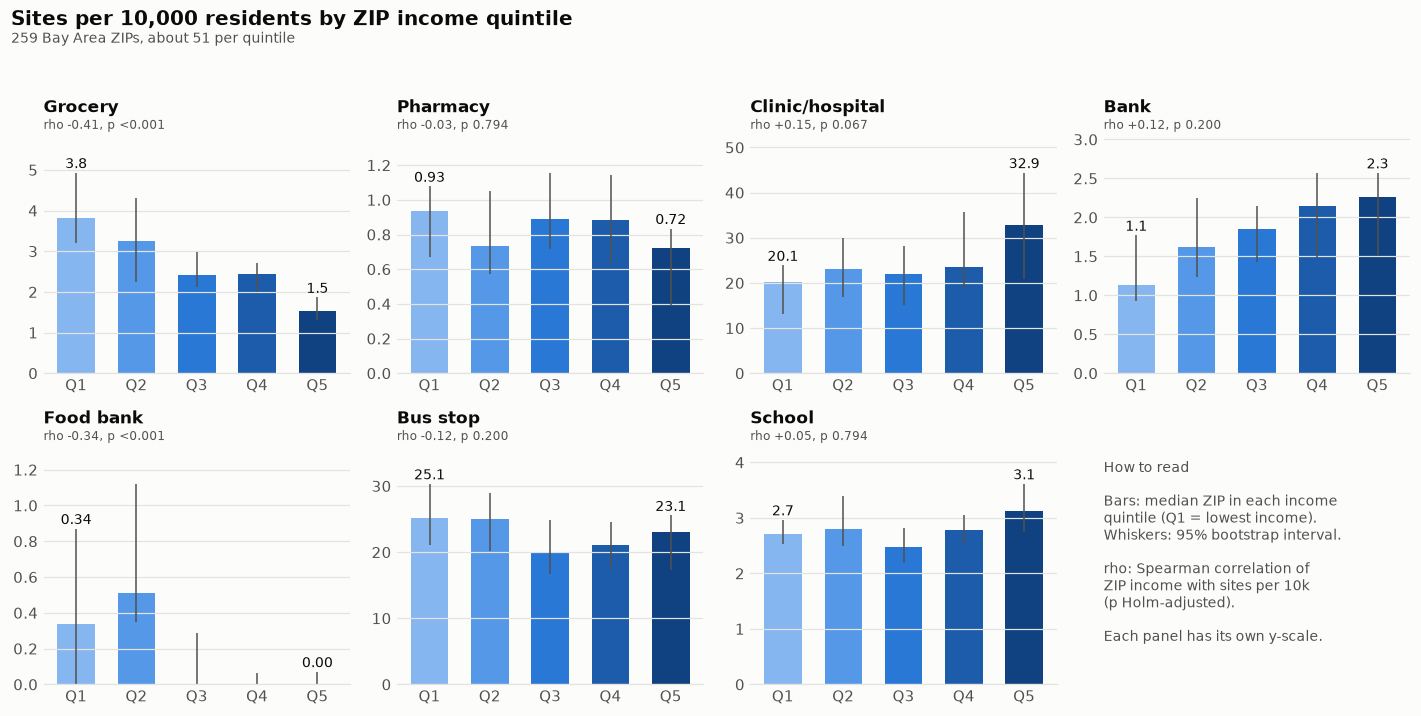

In [7]:
# CHART 1: one small panel per service, bars = median ZIP, whiskers = 95% bootstrap interval.
# If the median ZIP has 0 sites in every quintile (likely for food banks), that panel shows the mean instead.
fig, axes = plt.subplots(2, 4, figsize=(13, 6.6))
for ax, t in zip(axes.flat, TYPES):
    d = avail_long[avail_long["type"] == t].set_index("quintile").loc[Q]
    use_mean = (d["median_per_10k"] == 0).all()
    v, lo, hi = (d["mean_per_10k"], d["mean_ci_low"], d["mean_ci_high"]) if use_mean else \
                (d["median_per_10k"], d["ci_low"], d["ci_high"])
    err = np.vstack([v - lo, hi - v]).clip(min=0)
    ax.bar(Q, v, color=Q_COLORS, width=0.62, yerr=err, error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 0})
    for q in ["Q1", "Q5"]:                              # label the two ends only, above the whisker
        top = np.nanmax([v[q], hi[q]])
        ax.annotate(f"{v[q]:.1f}" if v[q] >= 1 else f"{v[q]:.2f}", (Q.index(q), top), textcoords="offset points",
                    xytext=(0, 3), ha="center", fontsize=9, color=INK)
    ax.set_ylim(0, max(np.nanmax(hi.values), np.nanmax(v.values), 0.01) * 1.18)
    r = avail.set_index("service").loc[LABEL[t]]
    ax.set_title(LABEL[t] + (" (mean ZIP)" if use_mean else ""), loc="left", pad=16)
    ax.text(0, 1.02, f"rho {r['spearman_rho']:+.2f}, p {fmt_p(r['p_holm'])}", transform=ax.transAxes,
            fontsize=8, color=INK2, va="bottom")
    ax.tick_params(length=0)
axes.flat[-1].axis("off")
axes.flat[-1].text(0, 0.95, "How to read\n\nBars: median ZIP in each income\nquintile (Q1 = lowest income).\n"
                   "Whiskers: 95% bootstrap interval.\n\nrho: Spearman correlation of\nZIP income with sites per 10k\n"
                   "(p Holm-adjusted).\n\nEach panel has its own y-scale.", va="top", fontsize=9, color=INK2)
fig.suptitle("Sites per 10,000 residents by ZIP income quintile", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.935, f"{len(zq)} Bay Area ZIPs, about {len(zq)//5} per quintile", fontsize=9, color=INK2)
fig.tight_layout(rect=(0, 0, 1, 0.93))
save(fig, "01_availability_by_quintile.png")
plt.show()

## 2. Deserts: how often a quintile has none of a service

`has_none` = the ZIP has zero sites of that type. Per quintile: the share of ZIPs with none, and how many residents live in such ZIPs.
The **Cochran-Armitage trend test** asks whether that share rises or falls steadily from Q1 to Q5 (z < 0 means fewer deserts as income rises). P-values are Holm-adjusted.

Larger ZIPs are more likely to contain at least one of anything, so compare `median_zip_population` in the quintile table before reading a gap as an income effect.

In [8]:
none_rows, none_long = [], []
for t in TYPES:
    col = f"has_none_{t}"
    gq = zq.groupby("income_group", observed=True)
    k, n = gq[col].sum().reindex(Q), gq.size().reindex(Q)
    pop_none = zq[zq[col]].groupby("income_group", observed=True)["population"].sum().reindex(Q, fill_value=0)
    z, p = trend_test(k.values, n.values)
    for q in Q:
        none_long.append({"service": LABEL[t], "type": t, "quintile": q, "zips_with_none": int(k[q]),
                          "zips": int(n[q]), "share_with_none": k[q] / n[q],
                          "residents_in_zips_with_none": int(pop_none[q])})
    none_rows.append({"service": LABEL[t], **{q: k[q] / n[q] for q in Q},
                      "Q1 count": f"{int(k['Q1'])}/{int(n['Q1'])}", "Q5 count": f"{int(k['Q5'])}/{int(n['Q5'])}",
                      "all ZIPs": zq[col].mean(), "trend_z": z, "p": p})

none_long = pd.DataFrame(none_long)
none = pd.DataFrame(none_rows)
none["p_holm"] = holm(none["p"])
none_long.to_csv(f"{RES}/02_has_none_by_quintile.csv", index=False)
none.to_csv(f"{RES}/02_has_none_summary.csv", index=False)

print("Share of ZIPs with NONE of the service, by income quintile")
fmt = {q: "{:.0%}" for q in Q} | {"all ZIPs": "{:.0%}", "trend_z": "{:+.2f}", "p": "{:.3f}", "p_holm": "{:.3f}"}
none.set_index("service").style.format(fmt, na_rep="n/a")

Share of ZIPs with NONE of the service, by income quintile


,Q1,Q2,Q3,Q4,Q5,Q1 count,Q5 count,all ZIPs,trend_z,p,p_holm
service,,,,,,,,,,,
Grocery,6%,8%,6%,0%,12%,3/52,6/52,6%,+0.36,0.716,1.000
Pharmacy,23%,21%,14%,17%,29%,12/52,15/52,21%,+0.43,0.666,1.000
Clinic/hospital,4%,2%,4%,2%,4%,2/52,2/52,3%,-0.00,1.000,1.000
Bank,17%,15%,10%,8%,19%,9/52,10/52,14%,-0.25,0.800,1.000
Food bank,38%,27%,51%,63%,63%,20/52,33/52,49%,+3.95,0.000,0.001
Bus stop,6%,4%,6%,2%,8%,3/52,4/52,5%,+0.20,0.841,1.000
School,8%,2%,4%,2%,4%,4/52,2/52,4%,-0.91,0.363,1.000


In [9]:
# Residents living in a ZIP with none of the service
none_long.pivot(index="service", columns="quintile", values="residents_in_zips_with_none") \
    .reindex([LABEL[t] for t in TYPES]).style.format("{:,.0f}")

quintile,Q1,Q2,Q3,Q4,Q5
service,,,,,
Grocery,"6,117","6,358","17,179",0,"24,440"
Pharmacy,"79,246","80,255","30,181","92,308","123,528"
Clinic/hospital,"2,962","1,542","2,740","25,574","2,743"
Bank,"22,914","35,500","20,310","50,020","110,182"
Food bank,"332,972","327,252","918,375","845,355","640,085"
Bus stop,"4,826","4,544","17,710","25,574","18,938"
School,"10,324","2,344","2,308","4,579","2,738"


In [10]:
# The lowest-income ZIPs that lack an everyday service (for the map and the "where to act" slide)
core = ["grocery", "pharmacy", "clinic", "bank"]
q1 = zq[zq["income_group"] == "Q1"].copy()
q1["missing"] = q1.apply(lambda r: ", ".join(LABEL[t] for t in core if r[f"has_none_{t}"]), axis=1)
q1_gaps = q1.loc[q1["missing"] != "", ["zip", "county", "population", "median_income", "missing"]] \
            .sort_values("population", ascending=False)
q1_gaps.to_csv(f"{RES}/02_q1_zips_missing_services.csv", index=False)
print(len(q1_gaps), "of", len(q1), "Q1 ZIPs have no grocery, pharmacy, clinic or bank site")
q1_gaps.head(15)

12 of 52 Q1 ZIPs have no grocery, pharmacy, clinic or bank site


,zip,county,population,median_income,missing
172,94124,San Francisco,34475,80509.0,Pharmacy
171,94305,Santa Clara,18509,83088.0,Pharmacy
111,94572,Contra Costa,8976,91484.0,"Pharmacy, Bank"
121,94599,Napa,3348,80372.0,Pharmacy
148,94038,San Mateo,2683,99680.0,"Grocery, Pharmacy, Bank"
247,94130,San Francisco,2429,93269.0,"Pharmacy, Bank"
48,94514,Contra Costa,1953,76511.0,"Pharmacy, Clinic/hospital, Bank"
162,94511,Contra Costa,1864,74972.0,"Grocery, Pharmacy, Bank"
6,95421,Sonoma,1570,78906.0,"Grocery, Pharmacy, Bank"
42,94924,Marin,1372,101458.0,"Pharmacy, Bank"


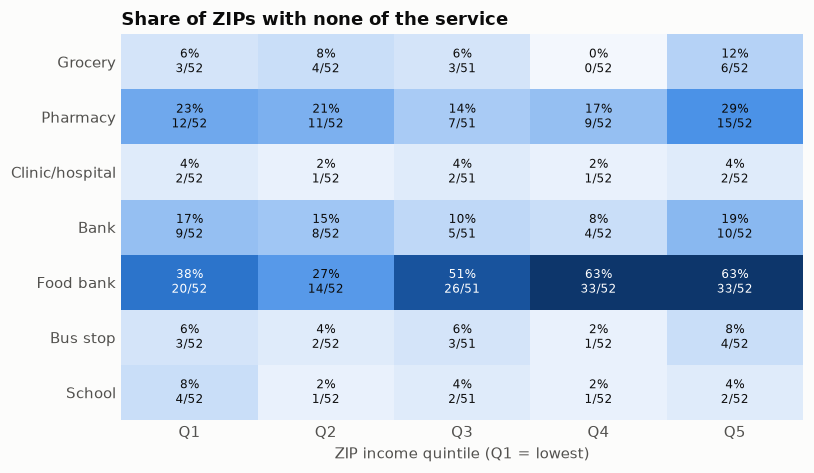

In [11]:
# CHART 2: share of ZIPs with none, services x quintiles
mat = none.set_index("service")[Q].astype(float)
fig, ax = plt.subplots(figsize=(7.5, 4.4))
im = ax.imshow(mat.values, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "blue", ["#f3f7fd", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"]), vmin=0, vmax=max(0.5, mat.values.max()), aspect="auto")
cnt = none_long.pivot(index="service", columns="quintile", values="zips_with_none").reindex(mat.index)
tot = none_long.pivot(index="service", columns="quintile", values="zips").reindex(mat.index)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        ax.text(j, i, f"{v:.0%}\n{int(cnt.values[i, j])}/{int(tot.values[i, j])}", ha="center", va="center",
                fontsize=8, color="white" if v > 0.3 else INK)
ax.set_xticks(range(5), Q)
ax.set_yticks(range(len(mat)), mat.index)
ax.grid(False)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Share of ZIPs with none of the service", loc="left", fontsize=12)
ax.set_xlabel("ZIP income quintile (Q1 = lowest)")
fig.tight_layout()
save(fig, "02_has_none_by_quintile.png")
plt.show()

## 3. Quality: ratings by income quintile

Only grocery, pharmacy, bank and clinic, and only places with **10+ reviews** (`enough_reviews`). Each place counts once; for clinics this is every listing with 10+ reviews, since each listing is a separate provider with its own reviews.

Per quintile:
* **median** and **mean** rating
* **low-rated share**: the share of places at or below the Bay Area 25th-percentile rating for that service type (pharmacies are compared with pharmacies, banks with banks)

Uncertainty: **Q5 − Q1 difference in mean rating, with a 95% interval from a cluster bootstrap that resamples ZIPs** (places in the same ZIP are not independent, so resampling places would overstate certainty).
Trend: Spearman correlation of rating with ZIP income, at place level and at ZIP level (one median rating per ZIP; more conservative).

In [12]:
pl = places.merge(zq[["zip", "income_group", "median_income", "county"]], on="zip", how="inner")
print("places in ZIPs with an income group:", len(pl), "of", len(places))

rated_all = pl[pl["type"].isin(RATED) & pl["enough_reviews"] & pl["rating_clean"].notna()].copy()
cut = rated_all.groupby("type")["rating_clean"].quantile(0.25)          # 25th percentile per service type
rated_all["low_rated"] = rated_all["rating_clean"] <= rated_all["type"].map(cut)
print("low-rated cutoff (rating at or below):", {LABEL[t]: cut[t] for t in RATED if t in cut})
print("rated places (10+ reviews):", rated_all.groupby("type").size().rename(LABEL).to_dict())

def cluster_boot_diff(d, col, reps=2000):
    """Q5 minus Q1 difference in the mean of `col`, with a 95% interval from resampling ZIPs in each group."""
    rng = np.random.default_rng(SEED)
    draws = []
    for q in ["Q1", "Q5"]:
        z = d[d["income_group"] == q].groupby("zip")[col].agg(["sum", "count"])
        if len(z) < 2:
            return np.nan, np.nan, np.nan
        idx = rng.integers(0, len(z), size=(reps, len(z)))
        draws.append(z["sum"].values[idx].sum(1) / z["count"].values[idx].sum(1))
    diff = draws[1] - draws[0]
    point = d.loc[d["income_group"] == "Q5", col].mean() - d.loc[d["income_group"] == "Q1", col].mean()
    lo, hi = np.percentile(diff, [2.5, 97.5])
    return point, lo, hi

def rating_tables(df, variant):
    long, summ = [], []
    for t in RATED:
        d = df[df["type"] == t]
        gq = d.groupby("income_group", observed=True)
        s = pd.DataFrame({"places": gq.size(), "zips": gq["zip"].nunique(),
                          "median": gq["rating_clean"].median(), "mean": gq["rating_clean"].mean(),
                          "low_rated_share": gq["low_rated"].mean()}).reindex(Q)
        for q in Q:
            long.append({"variant": variant, "service": LABEL[t], "quintile": q, **s.loc[q].to_dict()})
        rho, p = spearman(d["median_income"], d["rating_clean"])
        zl = d.groupby("zip").agg(r=("rating_clean", "median"), inc=("median_income", "first"))
        rho_z, p_z = spearman(zl["inc"], zl["r"])
        diff, lo, hi = cluster_boot_diff(d, "rating_clean")
        ldiff, llo, lhi = cluster_boot_diff(d.assign(low=d["low_rated"].astype(float)), "low")
        summ.append({"variant": variant, "service": LABEL[t], "places": len(d),
                     "Q1 median": s.loc["Q1", "median"], "Q5 median": s.loc["Q5", "median"],
                     "Q1 mean": s.loc["Q1", "mean"], "Q5 mean": s.loc["Q5", "mean"],
                     "Q5-Q1 mean": diff, "ci_low": lo, "ci_high": hi,
                     "Q1 low-rated": s.loc["Q1", "low_rated_share"], "Q5 low-rated": s.loc["Q5", "low_rated_share"],
                     "Q5-Q1 low-rated": ldiff, "low_ci_low": llo, "low_ci_high": lhi,
                     "rho_place": rho, "p_place": p, "rho_zip": rho_z, "p_zip": p_z})
    summ = pd.DataFrame(summ)
    summ["p_place_holm"] = holm(summ["p_place"])
    summ["p_zip_holm"] = holm(summ["p_zip"])
    return pd.DataFrame(long), summ

rate_long, rate_sum = rating_tables(rated_all, "10+ reviews (main)")
rate_long.to_csv(f"{RES}/03_ratings_by_quintile.csv", index=False)
rate_sum.to_csv(f"{RES}/03_ratings_summary.csv", index=False)

print("\nMedian rating by income quintile (places with 10+ reviews)")
rate_long.pivot(index="service", columns="quintile", values="median").reindex([LABEL[t] for t in RATED])

places in ZIPs with an income group: 82139 of 89455
low-rated cutoff (rating at or below): {'Grocery': np.float64(4.1), 'Pharmacy': np.float64(3.2), 'Clinic/hospital': np.float64(4.3), 'Bank': np.float64(2.9)}
rated places (10+ reviews): {'Bank': 1091, 'Clinic/hospital': 7413, 'Grocery': 1946, 'Pharmacy': 598}



Median rating by income quintile (places with 10+ reviews)


quintile,Q1,Q2,Q3,Q4,Q5
service,,,,,
Grocery,4.3,4.30,4.3,4.3,4.3
Pharmacy,3.9,3.85,3.8,3.7,3.5
Clinic/hospital,4.7,4.80,4.8,4.8,4.9
Bank,3.5,3.50,3.4,3.3,3.5


In [13]:
print("Mean rating and low-rated share by quintile")
show = rate_long.pivot(index="service", columns="quintile", values=["mean", "low_rated_share", "places"]) \
                .reindex([LABEL[t] for t in RATED])
show.style.format({c: ("{:.2f}" if c[0] == "mean" else "{:.0%}" if c[0] == "low_rated_share" else "{:,.0f}")
                   for c in show.columns})

Mean rating and low-rated share by quintile


In [14]:
print("Q5 minus Q1: positive = richer ZIPs rate higher. Intervals resample ZIPs.")
cols = ["service", "places", "Q1 mean", "Q5 mean", "Q5-Q1 mean", "ci_low", "ci_high",
        "Q1 low-rated", "Q5 low-rated", "rho_place", "p_place_holm", "rho_zip", "p_zip_holm"]
rate_sum[cols].set_index("service").style.format({
    "places": "{:,.0f}", "Q1 mean": "{:.2f}", "Q5 mean": "{:.2f}", "Q5-Q1 mean": "{:+.2f}",
    "ci_low": "{:+.2f}", "ci_high": "{:+.2f}", "Q1 low-rated": "{:.0%}", "Q5 low-rated": "{:.0%}",
    "rho_place": "{:+.2f}", "p_place_holm": "{:.3f}", "rho_zip": "{:+.2f}", "p_zip_holm": "{:.3f}"}, na_rep="n/a")

Q5 minus Q1: positive = richer ZIPs rate higher. Intervals resample ZIPs.


,places,Q1 mean,Q5 mean,Q5-Q1 mean,ci_low,ci_high,Q1 low-rated,Q5 low-rated,rho_place,p_place_holm,rho_zip,p_zip_holm
service,,,,,,,,,,,,
Grocery,"1,946",4.26,4.26,+0.01,-0.06,+0.08,35%,38%,+0.03,0.530,+0.02,0.710
Pharmacy,598,3.84,3.41,-0.43,-0.62,-0.25,16%,40%,-0.17,0.000,-0.25,0.001
Clinic/hospital,"7,413",4.35,4.65,+0.29,+0.19,+0.41,37%,17%,+0.13,0.000,+0.37,0.000
Bank,"1,091",3.53,3.48,-0.06,-0.18,+0.06,19%,29%,-0.03,0.530,-0.12,0.161


In [15]:
# ROBUSTNESS: does the rating gap survive (a) dropping chains, (b) a stricter 25+ review cutoff?
_, rob_ind = rating_tables(rated_all[~rated_all["is_chain"]], "Independents only")
_, rob_25 = rating_tables(rated_all[rated_all["reviews_count"] >= 25], "25+ reviews")
robust = pd.concat([rate_sum, rob_ind, rob_25], ignore_index=True)
robust.to_csv(f"{RES}/03_ratings_robustness.csv", index=False)
robust.pivot(index="service", columns="variant", values="Q5-Q1 mean") \
      .reindex([LABEL[t] for t in RATED]).round(2)

variant,10+ reviews (main),25+ reviews,Independents only
service,,,
Grocery,0.01,-0.01,0.04
Pharmacy,-0.43,-0.52,0.06
Clinic/hospital,0.29,0.25,0.30
Bank,-0.06,0.01,0.10


In [16]:
# CONTEXT: review volume and chain share. Fewer reviews per place means ratings are less reliable,
# and is itself a finding about who writes reviews. Chains rate differently from independents.
vol = pl[pl["type"].isin(RATED)].groupby(["type", "income_group"], observed=True).agg(
    places=("place_id", "size"), median_reviews=("reviews_count", "median"),
    share_10plus_reviews=("enough_reviews", "mean"), chain_share=("is_chain", "mean")).reset_index()
vol["service"] = vol["type"].map(LABEL)
vol.to_csv(f"{RES}/03_review_volume_by_quintile.csv", index=False)
vt = vol.pivot(index="service", columns="income_group", values=["median_reviews", "share_10plus_reviews", "chain_share"]) \
        .reindex([LABEL[t] for t in RATED])
vt.style.format({c: ("{:,.0f}" if c[0] == "median_reviews" else "{:.0%}") for c in vt.columns})

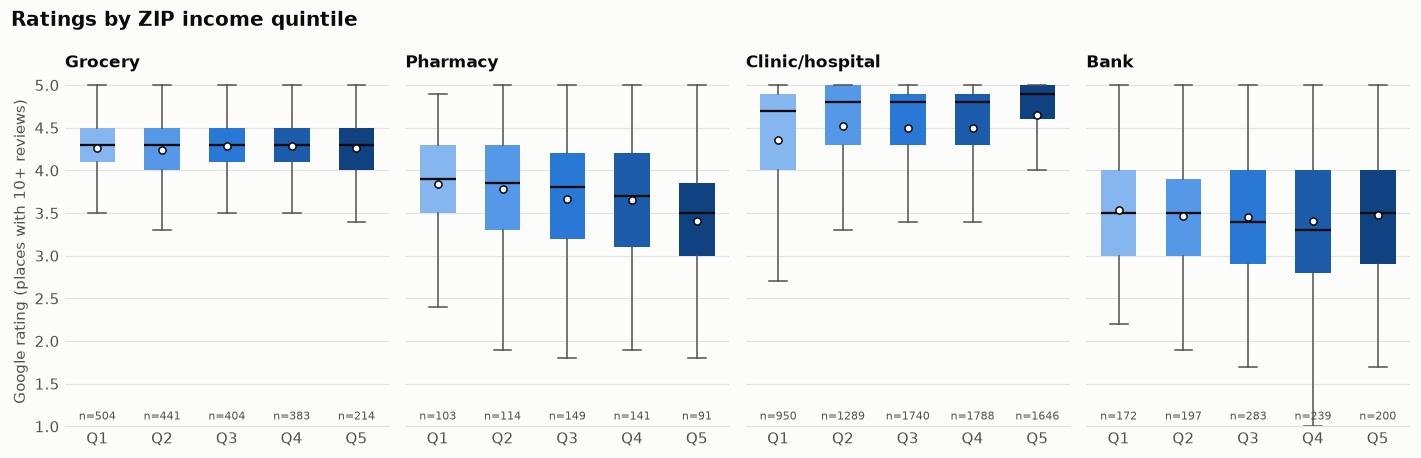

In [17]:
# CHART 3: rating distributions by quintile (box = middle half of places, line = median, dot = mean)
fig, axes = plt.subplots(1, 4, figsize=(13, 4.2), sharey=True)
for ax, t in zip(axes, RATED):
    d = rated_all[rated_all["type"] == t]
    data = [d.loc[d["income_group"] == q, "rating_clean"].values for q in Q]
    keep = [i for i, v in enumerate(data) if len(v)]
    bp = ax.boxplot([data[i] for i in keep], positions=keep, widths=0.55, patch_artist=True, showfliers=False,
                    medianprops={"color": INK, "linewidth": 1.5}, whiskerprops={"color": INK2},
                    capprops={"color": INK2}, boxprops={"linewidth": 0})
    for patch, i in zip(bp["boxes"], keep):
        patch.set_facecolor(Q_COLORS[i])
    ax.scatter(keep, [data[i].mean() for i in keep], s=22, color="white", edgecolor=INK, zorder=3, linewidth=1)
    for i in keep:
        ax.text(i, 1.08, f"n={len(data[i])}", ha="center", fontsize=7.5, color=INK2)
    ax.set_xticks(range(5), Q)
    ax.set_title(LABEL[t], loc="left")
    ax.set_ylim(1, 5.1)
    ax.tick_params(length=0)
axes[0].set_ylabel("Google rating (places with 10+ reviews)")
fig.suptitle("Ratings by ZIP income quintile", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "03_ratings_by_quintile.png")
plt.show()

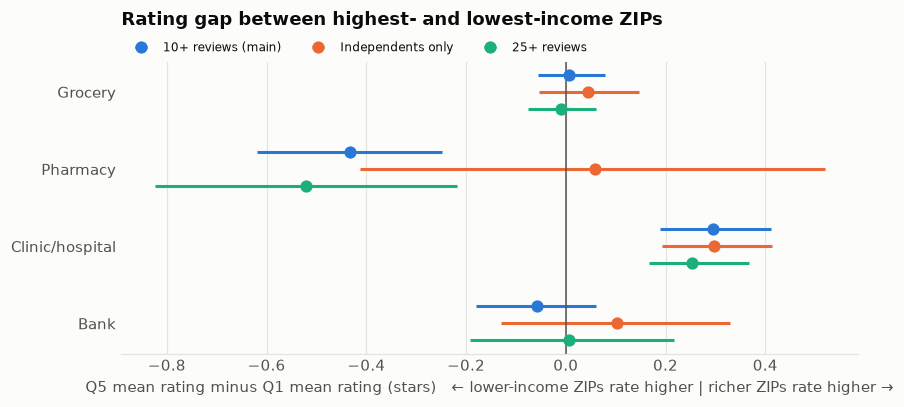

In [18]:
# CHART 4: Q5 minus Q1 mean rating with 95% ZIP-cluster bootstrap interval (main + robustness variants)
variants = ["10+ reviews (main)", "Independents only", "25+ reviews"]
vcolors = ["#2a78d6", "#eb6834", "#1baf7a"]
fig, ax = plt.subplots(figsize=(8, 3.8))
for k, (v, c) in enumerate(zip(variants, vcolors)):
    d = robust[robust["variant"] == v].set_index("service").reindex([LABEL[t] for t in RATED])
    y = np.arange(len(d)) + (k - 1) * 0.22
    ax.errorbar(d["Q5-Q1 mean"], y, xerr=[(d["Q5-Q1 mean"] - d["ci_low"]).clip(lower=0),
                (d["ci_high"] - d["Q5-Q1 mean"]).clip(lower=0)], fmt="o", color=c, ms=7,
                elinewidth=2, capsize=0, label=v)
ax.axvline(0, color=INK2, linewidth=1)
ax.set_yticks(range(len(RATED)), [LABEL[t] for t in RATED])
ax.invert_yaxis()
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.tick_params(length=0)
ax.set_xlabel("Q5 mean rating minus Q1 mean rating (stars)   ← lower-income ZIPs rate higher | richer ZIPs rate higher →")
ax.set_title("Rating gap between highest- and lowest-income ZIPs", loc="left", fontsize=12, pad=24)
ax.legend(frameon=False, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, borderaxespad=0.2)
fig.tight_layout()
save(fig, "04_rating_gap_q5_minus_q1.png")
plt.show()

## 4. What people complain about: 1-2 star clinic reviews (exploratory)

The Reviews file only overlaps with 112 of our places, all clinics, so this section covers clinics only. ZIPs are pooled into **lower income (Q1-Q2)** vs. **higher income (Q4-Q5)**; Q3 is left out so the contrast is clean.

* **Themes:** each review is tagged with every theme whose keywords it contains (one review can have several). We compare the share of reviews mentioning each theme with Fisher's exact test (Holm-adjusted).
* **Distinctive words:** words used by a larger share of reviews on one side than the other (smoothed log ratio, words in at least 8 reviews).

Keyword tags are a rough first pass. Before quoting a theme on a slide, read a sample (set `SHOW_REVIEWS = True` below), and paraphrase rather than quote.

In [19]:
if not HAVE_REVIEWS:
    print("Skipped: reviews_low.csv not found.")
else:
    cl = rev[rev["service_type"] == "clinic/hospital"].copy()
    cl = cl.merge(zq[["zip", "income_group"]], on="zip", how="left")
    cl["side"] = np.select([cl["income_group"].isin(["Q1", "Q2"]), cl["income_group"].isin(["Q4", "Q5"])],
                           [LOWER, HIGHER], default="Q3 or no income group")
    cl["text"] = cl["review"].fillna("").astype(str).str.lower()
    cl["has_text"] = cl["text"].str.strip() != ""
    cl["words"] = cl["text"].str.split().str.len()

    cov = cl.groupby(cl["income_group"].astype(str).replace("nan", "no group")).agg(
        reviews=("review_id", "size"), clinics=("place_id", "nunique"), zips=("zip", "nunique"))
    print("Coverage by quintile")
    display(cov)

    sides = cl[cl["side"].isin([LOWER, HIGHER])]
    side_tab = sides.groupby("side").agg(
        reviews=("review_id", "size"), with_text=("has_text", "sum"), clinics=("place_id", "nunique"),
        zips=("zip", "nunique"), share_1_star=("review_rating", lambda s: (s <= 1).mean()),
        median_words=("words", "median")).reindex([LOWER, HIGHER])
    side_tab["low_reviews_per_clinic"] = side_tab["reviews"] / side_tab["clinics"]
    top_share = sides.groupby("side")["place_id"].apply(lambda s: s.value_counts().head(5).sum() / len(s))
    side_tab["share_from_top_5_clinics"] = top_share.reindex([LOWER, HIGHER])
    a = sides[sides["side"] == LOWER]["review_rating"].le(1)
    b = sides[sides["side"] == HIGHER]["review_rating"].le(1)
    p_star = stats.fisher_exact([[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]]).pvalue if len(a) and len(b) else np.nan
    side_tab.to_csv(f"{RES}/04_complaints_coverage.csv")
    print("Lower vs. higher income. 1-star share difference: Fisher p =", fmt_p(p_star))
    display(side_tab.style.format({"share_1_star": "{:.0%}", "low_reviews_per_clinic": "{:.1f}",
                           "share_from_top_5_clinics": "{:.0%}", "median_words": "{:.0f}"}))

Skipped: reviews_low.csv not found.


In [20]:
if not HAVE_REVIEWS:
    print("Skipped: reviews_low.csv not found.")
else:
    THEMES = {
        "Wait times / delays":        r"\bwait(?:ed|ing|s)?\b|\bdelay(?:ed|s)?\b|\btook forever\b|\blong time\b|\blate\b|\bminutes\b|\bhours?\b",
        "Rude / dismissive staff":    r"\brude(?:ly|ness)?\b|\bdisrespect\w*|\bunprofessional\b|\battitude\b|\bcondescend\w*|\bdismissive\b|\byell(?:ed|ing)?\b|\bmean\b",
        "Appointments / scheduling":  r"\bappointments?\b|\bappt\b|\bschedul\w*|\bresched\w*|\bcancel+(?:ed|led|ation|s)?\b|\bno.show\b",
        "Phone / getting a response": r"\bphones?\b|\bcall(?:ed|ing|s)?\b|\bvoicemail\b|\bnever (?:heard|got) back\b|\bcall(?:ed)? back\b|\banswer\w*|\bemail\w*|\bportal\b",
        "Billing / cost / insurance": r"\bbill(?:ed|ing|s)?\b|\bcharg\w*|\binsurance\b|\bco-?pay\w*|\bcosts?\b|\bexpensive\b|\bpaid\b|\bpay(?:ment)?\b|\$\d|\brefund\w*|\bcollections?\b|\bmedi-?cal\b|\bmedicare\b",
        "Care quality / not listened to": r"\bmisdiagnos\w*|\bwrong\b|\bdidn'?t (?:listen|examine|care|even)\b|\bnot listen\w*|\brushed\b|\bincompeten\w*|\bignor\w*|\bcareless\b|\bnegligen\w*",
        "Prescriptions / referrals":  r"\bprescri\w*|\bmedications?\b|\bmeds\b|\brefill\w*|\breferr\w*|\bpharmac\w*",
        "Front desk / reception":     r"\bfront (?:desk|office)\b|\breceptionist\w*|\breception\b",
        "Language / interpreter":     r"\benglish\b|\bspanish\b|\binterpret\w*|\btranslat\w*|\blanguage\b",
    }
    txt = sides[sides["has_text"]].copy()
    for name, pat in THEMES.items():
        txt[name] = txt["text"].str.contains(pat, regex=True)

    trows = []
    nL, nH = (txt["side"] == LOWER).sum(), (txt["side"] == HIGHER).sum()
    for name in THEMES:
        kL = int(txt.loc[txt["side"] == LOWER, name].sum())
        kH = int(txt.loc[txt["side"] == HIGHER, name].sum())
        p = stats.fisher_exact([[kL, nL - kL], [kH, nH - kH]]).pvalue if nL and nH else np.nan
        trows.append({"theme": name, "lower_share": kL / nL if nL else np.nan, "higher_share": kH / nH if nH else np.nan,
                      "lower_n": f"{kL}/{nL}", "higher_n": f"{kH}/{nH}", "p": p})
    themes = pd.DataFrame(trows)
    themes["diff_pts"] = (themes["lower_share"] - themes["higher_share"]) * 100
    themes["p_holm"] = holm(themes["p"])
    themes = themes.sort_values("lower_share", ascending=False)
    themes.to_csv(f"{RES}/04_complaint_themes.csv", index=False)
    print(f"Share of 1-2 star clinic reviews mentioning each theme (reviews with text: lower {nL}, higher {nH})")
    display(themes.set_index("theme").style.format({"lower_share": "{:.0%}", "higher_share": "{:.0%}", "diff_pts": "{:+.0f}",
                                            "p": "{:.3f}", "p_holm": "{:.3f}"}, na_rep="n/a"))

Skipped: reviews_low.csv not found.


In [21]:
if not HAVE_REVIEWS:
    print("Skipped: reviews_low.csv not found.")
else:
    # CHART 5: complaint themes, lower vs. higher income
    d = themes.sort_values("lower_share")
    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    y = np.arange(len(d))
    ax.barh(y + 0.19, d["lower_share"], height=0.36, color=SIDE_COLORS[LOWER], label=f"{LOWER}, n={nL}")
    ax.barh(y - 0.19, d["higher_share"], height=0.36, color=SIDE_COLORS[HIGHER], label=f"{HIGHER}, n={nH}")
    ax.set_yticks(y, d["theme"])
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.tick_params(length=0)
    ax.set_xlabel("Share of 1-2 star reviews mentioning the theme")
    ax.set_title("What 1-2 star clinic reviews mention (exploratory, keyword tags)", loc="left", fontsize=12)
    ax.legend(frameon=False, fontsize=8, loc="lower right")      # legend order matches bar order (lower on top)
    fig.tight_layout()
    save(fig, "05_complaint_themes.png")
    plt.show()

Skipped: reviews_low.csv not found.


In [22]:
if not HAVE_REVIEWS:
    print("Skipped: reviews_low.csv not found.")
else:
    # Distinctive words: used by a bigger share of reviews on one side (counts each word once per review)
    STOP = set("""a about above after again against all am an and any are as at be because been before being below
    between both but by can could did do does doing down during each few for from further had has have having he her
    here hers him his how i if in into is it its itself just me more most my no nor not now of off on once only or other
    our out over own same she should so some such than that the their them then there these they this those through to
    too under until up very was we were what when where which while who whom why will with would you your yours im ive
    dont didnt doesnt wasnt isnt cant couldnt wont also get got go went one even really like told said back would
    there's it's i'm i've don't didn't can't won't wasn't doesn't isn't they're you're we're that's""".split())
    def tokens(s):
        return {w for w in re.findall(r"[a-z][a-z']+", s) if len(w) > 2 and w not in STOP}
    txt["tok"] = txt["text"].apply(tokens)
    from collections import Counter
    cL = Counter(w for ts in txt.loc[txt["side"] == LOWER, "tok"] for w in ts)
    cH = Counter(w for ts in txt.loc[txt["side"] == HIGHER, "tok"] for w in ts)
    vocab = [w for w in set(cL) | set(cH) if cL[w] + cH[w] >= 8]
    words = pd.DataFrame({"word": vocab, "lower_reviews": [cL[w] for w in vocab], "higher_reviews": [cH[w] for w in vocab]})
    if len(words):
        words["log_ratio"] = np.log((words["lower_reviews"] + 0.5) / (nL + 1)) - np.log((words["higher_reviews"] + 0.5) / (nH + 1))
        words.sort_values("log_ratio").to_csv(f"{RES}/04_distinctive_words.csv", index=False)
        top_l = words.nlargest(12, "log_ratio")[["word", "lower_reviews", "higher_reviews"]].reset_index(drop=True)
        top_h = words.nsmallest(12, "log_ratio")[["word", "higher_reviews", "lower_reviews"]].reset_index(drop=True)
        display(pd.concat({"more common in lower-income ZIPs": top_l, "more common in higher-income ZIPs": top_h}, axis=1))
    else:
        print("Too few reviews for a word comparison.")

Skipped: reviews_low.csv not found.


In [23]:
if not HAVE_REVIEWS:
    print("Skipped: reviews_low.csv not found.")
else:
    # HAND READ: set to True to print 20 random reviews per side for tagging by hand.
    # Left False so review text is not saved into the notebook outputs on GitHub. Never put reviewer names on slides.
    SHOW_REVIEWS = False
    if SHOW_REVIEWS:
        for s in [LOWER, HIGHER]:
            print("=" * 20, s)
            sample = txt[txt["side"] == s].sample(min(20, (txt["side"] == s).sum()), random_state=SEED)
            for _, r in sample.iterrows():
                print(f"[{int(r['review_rating'])} star] {r['review'][:400]}\n")

Skipped: reviews_low.csv not found.


## 5. Key findings (generated from the tables above)

Each line gives the number, the comparison group and the test, so it can go on a slide as is. The same text is saved to `results/key_findings.md`. Wording: "associated with", not "caused by".

In [24]:
def direction(a, b, more="more", fewer="fewer"):
    return more if a > b else fewer if a < b else "the same"

out = ["# Key findings (auto-generated by 03_analysis.ipynb)", "",
       f"Unit: {len(zq)} Bay Area ZIPs in five income quintiles of about {len(zq)//5} ZIPs each "
       f"(Q1 median income ${quint.loc['Q1', 'income_median']:,.0f}, Q5 ${quint.loc['Q5', 'income_median']:,.0f}).", "",
       "## Availability (sites per 10,000 residents, median ZIP)"]
for _, r in avail.iterrows():
    sig = "statistically clear" if r["p_holm"] < 0.05 else "not statistically clear"
    out.append(f"- {r['service']}: {r['Q1']:.2f} in Q1 vs. {r['Q5']:.2f} in Q5 "
               f"(pooled {r['pooled Q1']:.2f} vs. {r['pooled Q5']:.2f}); Spearman rho {r['spearman_rho']:+.2f}, "
               f"Holm p {fmt_p(r['p_holm'])} ({sig}).")
out += ["", "## ZIPs with none of the service"]
for _, r in none.iterrows():
    trend = "no test (no ZIP lacks it, or every ZIP does)" if pd.isna(r["trend_z"]) else \
            f"trend z {r['trend_z']:+.2f}, Holm p {fmt_p(r['p_holm'])}"
    out.append(f"- {r['service']}: {r['Q1']:.0%} of Q1 ZIPs ({r['Q1 count']}) vs. {r['Q5']:.0%} of Q5 ZIPs ({r['Q5 count']}); {trend}.")
out.append(f"- {len(q1_gaps)} of {len(q1)} Q1 ZIPs lack at least one of grocery, pharmacy, clinic or bank "
           f"(list: results/02_q1_zips_missing_services.csv).")
out += ["", "## Ratings (places with 10+ reviews)"]
for _, r in rate_sum.iterrows():
    ci = "interval excludes 0" if (r["ci_low"] > 0 or r["ci_high"] < 0) else "interval includes 0"
    out.append(f"- {r['service']}: median {r['Q1 median']:.1f} in Q1 vs. {r['Q5 median']:.1f} in Q5; mean {r['Q1 mean']:.2f} vs. "
               f"{r['Q5 mean']:.2f} (Q5-Q1 {r['Q5-Q1 mean']:+.2f}, 95% CI {r['ci_low']:+.2f} to {r['ci_high']:+.2f}, {ci}); "
               f"low-rated share {r['Q1 low-rated']:.0%} vs. {r['Q5 low-rated']:.0%}; n = {r['places']:,} places.")
for v, df_ in [("independents only", rob_ind), ("25+ reviews", rob_25)]:
    out.append(f"- Robustness ({v}): Q5-Q1 mean gap " +
               ", ".join(f"{r['service']} {r['Q5-Q1 mean']:+.2f}" for _, r in df_.iterrows()) + ".")
out += ["", "## Clinic complaints (exploratory, 1-2 star reviews)"]
if not HAVE_REVIEWS:
    out.append("- Not run: reviews_low.csv was not available.")
elif len(side_tab.dropna(how="all")):
    out.append(f"- Coverage: lower-income {int(side_tab.loc[LOWER, 'reviews'])} reviews from {int(side_tab.loc[LOWER, 'clinics'])} clinics; "
               f"higher-income {int(side_tab.loc[HIGHER, 'reviews'])} from {int(side_tab.loc[HIGHER, 'clinics'])} clinics.")
    for _, r in themes.head(4).iterrows():
        out.append(f"- {r['theme']}: {r['lower_share']:.0%} of lower-income vs. {r['higher_share']:.0%} of higher-income reviews "
                   f"(Holm p {fmt_p(r['p_holm'])}).")
    big = themes[themes["p_holm"] < 0.05]
    out.append("- Themes that differ after Holm adjustment: " + (", ".join(big["theme"]) if len(big) else "none") + ".")

text = "\n".join(out)
with open(f"{RES}/key_findings.md", "w", encoding="utf-8") as f:
    f.write(text + "\n")
print(text)

# Key findings (auto-generated by 03_analysis.ipynb)

Unit: 259 Bay Area ZIPs in five income quintiles of about 51 ZIPs each (Q1 median income $86,694, Q5 $222,986).

## Availability (sites per 10,000 residents, median ZIP)
- Grocery: 3.82 in Q1 vs. 1.53 in Q5 (pooled 4.57 vs. 1.91); Spearman rho -0.41, Holm p <0.001 (statistically clear).
- Pharmacy: 0.93 in Q1 vs. 0.72 in Q5 (pooled 1.00 vs. 0.95); Spearman rho -0.03, Holm p 0.794 (not statistically clear).
- Clinic/hospital: 20.14 in Q1 vs. 32.86 in Q5 (pooled 25.21 vs. 39.38); Spearman rho +0.15, Holm p 0.067 (not statistically clear).
- Bank: 1.13 in Q1 vs. 2.26 in Q5 (pooled 1.82 vs. 2.53); Spearman rho +0.12, Holm p 0.200 (not statistically clear).
- Food bank: 0.34 in Q1 vs. 0.00 in Q5 (pooled 0.80 vs. 0.19); Spearman rho -0.34, Holm p <0.001 (statistically clear).
- Bus stop: 25.09 in Q1 vs. 23.11 in Q5 (pooled 24.23 vs. 22.05); Spearman rho -0.12, Holm p 0.200 (not statistically clear).
- School: 2.71 in Q1 vs. 3.11 in Q5 (po

## Methodology

**Unit of analysis and income groups.** The unit is the ZIP code (Census ZCTA) in the nine Bay Area counties: 261 ZIPs with at least 1,000 residents. Each ZIP gets its ACS 2020-2024 5-year median household income, and the 259 ZIPs with an income estimate are split into five equal-count quintiles with `pd.qcut` (Q1 = lowest-income fifth of ZIPs, Q5 = highest). We compare quintiles rather than dollar amounts because the Census caps median income at $250,001: the 12 capped ZIPs sort correctly into Q5, but their true incomes are unknown. Places are joined to ZIPs by the 5-digit ZIP in their address (notebook 01), and services are counted per ZIP (notebook 02).

**1. Availability.** For each ZIP and service, *sites per 10,000 residents* = distinct sites ÷ population × 10,000. A "site" is one address per service type (`is_site`), so a medical building with many listed providers counts once. Every bus stop counts as its own site. For each quintile we report the **median ZIP**, which is resistant to a few dense downtown ZIPs, with a 95% bootstrap interval (2,000 resamples of the quintile's ZIPs). We also report the **pooled rate** (all sites ÷ all residents in the quintile). The trend is the **Spearman rank correlation** between ZIP median income and the rate across all 259 ZIPs. A rank method fits because counts are skewed and income is capped. We test seven services, so p-values are **Holm-adjusted**.

**2. ZIPs with none.** `has_none` = zero sites of that type in the ZIP. Per quintile we report the share of ZIPs with none and the number of residents living in those ZIPs. The **Cochran-Armitage trend test** checks whether that share changes steadily from Q1 to Q5 (Holm-adjusted). ZIP size is a confounder here, because bigger ZIPs are more likely to contain at least one of anything. Read this alongside the median ZIP population per quintile (table 00).

**3. Ratings.** Ratings are used only for grocery, pharmacy, bank and clinic. Schools, bus stops and food banks have too few reviews. We keep only places with **10+ reviews**, since ratings from a handful of reviews swing to 1 or 5 stars. A rating of 0 means "no reviews" and was set to missing in notebook 01. Each place is one observation. Per quintile we report the median rating, the mean rating, and the **low-rated share**: the share of places at or below the Bay Area 25th-percentile rating for that service type, so each type is judged against its own baseline. The main uncertainty measure is the **Q5 − Q1 difference in mean rating with a 95% cluster-bootstrap interval that resamples ZIPs**, because places in the same ZIP share conditions and are not independent. We also report Spearman correlations at the place level and the ZIP level (one median rating per ZIP; more conservative). **Robustness checks:** rerun without chains, and rerun with a 25+ review cutoff. **Context:** median review count, share with 10+ reviews, and chain share by quintile.

**4. Clinic complaints (exploratory).** The Reviews file overlaps with only 112 of our places, all clinics: 646 one- and two-star reviews from 92 clinics in 60 ZIPs. That is too thin for ZIP or county comparisons, so reviews are pooled into lower-income (Q1-Q2) vs. higher-income (Q4-Q5) ZIPs, with Q3 dropped for a clean contrast. Each review is tagged with every theme whose keywords it contains. We compare the share of reviews mentioning each theme with **Fisher's exact test** (Holm-adjusted), and find distinctive words with a smoothed log ratio of the share of reviews using each word. We also report how concentrated each side is in its top 5 clinics: if a few clinics dominate, a theme may describe those clinics rather than the income group. Only low reviews were saved, so we cannot compare the *share* of reviews that are negative, only what negative reviews say. Reviewer names were never loaded. Review text is not printed in saved outputs, and slides should paraphrase.

**Reproducibility.** Every random step uses `SEED = 42`. All tables behind the charts are saved to `results/` and all charts to `figures/`, so the slides, the README and the Tableau dashboard can use the same numbers.

## Limitations

* **Association, not cause.** Income moves together with race, car ownership, language and population density (table 00), so a pattern by income quintile should not be credited to income alone.
* **ZIP averages hide variation.** A ZIP can mix very rich and very poor blocks, and the results say nothing about any one person.
* **A count inside the ZIP is not access.** A pharmacy just across a ZIP border, or one that closes at 5 PM, is not captured. This is why car-free households matter.
* **Ratings measure reviewer satisfaction, not quality of care,** and reviewers skew toward people with time, smartphones and English.
* **The scrape's coverage is unknown.** If Google Maps lists fewer places in lower-income ZIPs, "fewer services" could partly be a data gap. See the coverage check in the README.